In [15]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("../data/o_churn_synthetic.csv")

print("Размер датасета:", df.shape)
print("\nНазвания столбцов:")
print(df.columns.tolist())

display(df.head())

Размер датасета: (3000, 13)

Названия столбцов:
['subscriber_code', 'region', 'tariff', 'tenure_months', 'monthly_charge_som', 'internet_gb', 'support_calls_3m', 'autopay', 'days_since_topup', 'topups_3m', 'dropped_calls_pct', 'balance_som', 'churn']


,subscriber_code,region,tariff,tenure_months,monthly_charge_som,internet_gb,support_calls_3m,autopay,days_since_topup,topups_3m,dropped_calls_pct,balance_som,churn
0,503715,Бишкек,Базовый,47,264,12.6,1,0,37,4,2.28,103,1
1,844126,Джалал-Абадская,Смарт,54,472,19.9,0,1,12,7,1.40,184,0
2,885657,Чуйская,Базовый,1,291,12.9,0,1,3,9,2.98,11,0
3,255447,Ош,Базовый,29,273,7.1,0,0,17,6,2.16,137,0
4,651577,Ош,Смарт,60,402,14.0,2,1,12,9,2.92,39,0


In [16]:
# Проверяем типы данных
print("Типы данных:")
print(df.dtypes)

# Проверяем пропуски
print("\nКоличество пропусков по столбцам:")
print(df.isnull().sum())

# Проверяем дубликаты
print("\nКоличество дубликатов:", df.duplicated().sum())

# Проверяем распределение целевого класса
print("\nРаспределение churn:")
print(df["churn"].value_counts())

print("\nДоля каждого класса:")
print(df["churn"].value_counts(normalize=True).round(3))

Типы данных:
subscriber_code         int64
region                    str
tariff                    str
tenure_months           int64
monthly_charge_som      int64
internet_gb           float64
support_calls_3m        int64
autopay                 int64
days_since_topup        int64
topups_3m               int64
dropped_calls_pct     float64
balance_som             int64
churn                   int64
dtype: object

Количество пропусков по столбцам:
subscriber_code       0
region                0
tariff                0
tenure_months         0
monthly_charge_som    0
internet_gb           0
support_calls_3m      0
autopay               0
days_since_topup      0
topups_3m             0
dropped_calls_pct     0
balance_som           0
churn                 0
dtype: int64

Количество дубликатов: 0

Распределение churn:
churn
0    1886
1    1114
Name: count, dtype: int64

Доля каждого класса:
churn
0    0.629
1    0.371
Name: proportion, dtype: float64


In [17]:
from sklearn.model_selection import train_test_split

# Убираем код абонента: он является идентификатором, а не полезным признаком
X = df.drop(columns=["subscriber_code", "churn"])
y = df["churn"]

# Определяем категориальные и числовые признаки
categorical_features = ["region", "tariff"]
numeric_features = [
    "tenure_months",
    "monthly_charge_som",
    "internet_gb",
    "support_calls_3m",
    "autopay",
    "days_since_topup",
    "topups_3m",
    "dropped_calls_pct",
    "balance_som"
]

# Разделяем данные так, как требует задание
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    stratify=y,
    random_state=42
)

print("Размер X_train:", X_train.shape)
print("Размер X_test:", X_test.shape)

print("\nРаспределение классов в train:")
print(y_train.value_counts(normalize=True).round(3))

print("\nРаспределение классов в test:")
print(y_test.value_counts(normalize=True).round(3))

Размер X_train: (2400, 11)
Размер X_test: (600, 11)

Распределение классов в train:
churn
0    0.629
1    0.371
Name: proportion, dtype: float64

Распределение классов в test:
churn
0    0.628
1    0.372
Name: proportion, dtype: float64


In [18]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline

# Преобразуем категориальные признаки в числовые
preprocessor = ColumnTransformer(
    transformers=[
        (
            "cat",
            OneHotEncoder(handle_unknown="ignore"),
            categorical_features
        )
    ],
    remainder="passthrough"
)

print("Предобработка данных настроена!")

Предобработка данных настроена!


In [19]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import f1_score, roc_auc_score

# Дерево решений
tree_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", DecisionTreeClassifier(random_state=42))
])

tree_model.fit(X_train, y_train)

tree_train_pred = tree_model.predict(X_train)
tree_test_pred = tree_model.predict(X_test)
tree_test_proba = tree_model.predict_proba(X_test)[:, 1]

# Случайный лес со 100 деревьями
forest_default = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=100,
        random_state=42,
        n_jobs=-1
    ))
])

forest_default.fit(X_train, y_train)

forest_train_pred = forest_default.predict(X_train)
forest_test_pred = forest_default.predict(X_test)
forest_test_proba = forest_default.predict_proba(X_test)[:, 1]

# Собираем метрики в одну таблицу
comparison = pd.DataFrame([
    {
        "Модель": "Дерево решений",
        "F1 train": f1_score(y_train, tree_train_pred),
        "F1 test": f1_score(y_test, tree_test_pred),
        "ROC-AUC test": roc_auc_score(y_test, tree_test_proba)
    },
    {
        "Модель": "Случайный лес (100 деревьев)",
        "F1 train": f1_score(y_train, forest_train_pred),
        "F1 test": f1_score(y_test, forest_test_pred),
        "ROC-AUC test": roc_auc_score(y_test, forest_test_proba)
    }
])

comparison.round(3)

,Модель,F1 train,F1 test,ROC-AUC test
0,Дерево решений,1.0,0.508,0.600
1,Случайный лес (100 деревьев),1.0,0.552,0.756


In [20]:
# Случайный лес с OOB-оценкой
forest_oob = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=100,
        random_state=42,
        oob_score=True,
        n_jobs=-1
    ))
])

forest_oob.fit(X_train, y_train)

oob_score = forest_oob.named_steps["classifier"].oob_score_

print("Количество деревьев:", 100)
print("OOB score:", round(oob_score, 3))
print("ROC-AUC на тестовой выборке:",
      round(roc_auc_score(y_test, forest_oob.predict_proba(X_test)[:, 1]), 3))

Количество деревьев: 100
OOB score: 0.693
ROC-AUC на тестовой выборке: 0.756


/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/sklearn/ensemble/_forest.py:611: UserWarning: Some inputs do not have OOB scores. This probably means too few trees were used to compute any reliable OOB estimates.
  warn(


,Количество деревьев,OOB score
0,10,0.642
1,25,0.673
2,50,0.689
3,100,0.693
4,200,0.705
5,400,0.704


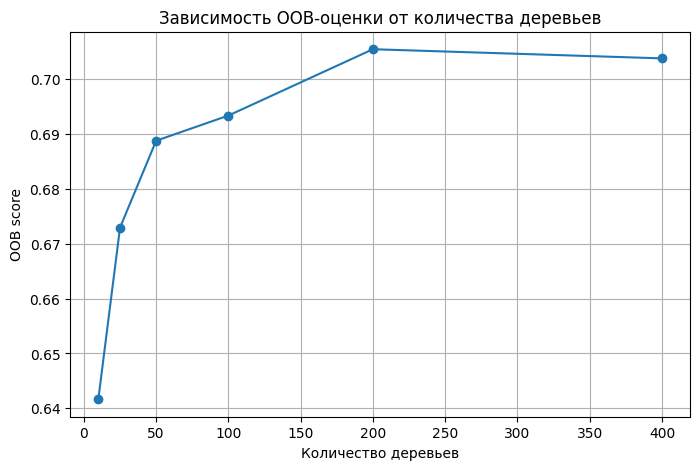

In [21]:
# Проверяем разное количество деревьев
n_trees_list = [10, 25, 50, 100, 200, 400]
oob_scores = []

# Преобразуем данные один раз
X_train_transformed = (
    forest_oob.named_steps["preprocessor"].transform(X_train)
)

for n_trees in n_trees_list:
    model = RandomForestClassifier(
        n_estimators=n_trees,
        random_state=42,
        oob_score=True,
        n_jobs=-1
    )

    model.fit(X_train_transformed, y_train)
    oob_scores.append(model.oob_score_)

# Выводим результаты в таблице
oob_results = pd.DataFrame({
    "Количество деревьев": n_trees_list,
    "OOB score": oob_scores
})

display(oob_results.round(3))

# Строим график
plt.figure(figsize=(8, 5))
plt.plot(n_trees_list, oob_scores, marker="o")
plt.xlabel("Количество деревьев")
plt.ylabel("OOB score")
plt.title("Зависимость OOB-оценки от количества деревьев")
plt.grid(True)
plt.show()

In [22]:
from sklearn.model_selection import GridSearchCV, StratifiedKFold

# 5 частей для кросс-валидации
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Случайный лес внутри Pipeline
forest_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        random_state=42,
        n_jobs=1
    ))
])

# Какие параметры проверяем
param_grid = {
    "classifier__n_estimators": [100, 300],
    "classifier__max_depth": [None, 6, 10],
    "classifier__min_samples_leaf": [1, 5, 20],
    "classifier__max_features": ["sqrt", 0.5]
}

# Ищем лучшую комбинацию по ROC-AUC
grid_search = GridSearchCV(
    estimator=forest_pipeline,
    param_grid=param_grid,
    scoring="roc_auc",
    cv=cv,
    n_jobs=-1,
    verbose=1
)

grid_search.fit(X_train, y_train)

print("Лучшие параметры:")
print(grid_search.best_params_)

print("\nЛучший средний ROC-AUC на кросс-валидации:")
print(round(grid_search.best_score_, 3))

Fitting 5 folds for each of 36 candidates, totalling 180 fits
Лучшие параметры:
{'classifier__max_depth': 6, 'classifier__max_features': 'sqrt', 'classifier__min_samples_leaf': 5, 'classifier__n_estimators': 300}

Лучший средний ROC-AUC на кросс-валидации:
0.769


In [23]:
from sklearn.metrics import f1_score, roc_auc_score

# Получаем настроенную модель
forest_tuned = grid_search.best_estimator_

# Делаем предсказания настроенного леса
tuned_train_pred = forest_tuned.predict(X_train)
tuned_test_pred = forest_tuned.predict(X_test)
tuned_test_proba = forest_tuned.predict_proba(X_test)[:, 1]

# Собираем результаты всех трёх моделей
comparison_final = pd.DataFrame([
    {
        "Модель": "Дерево решений",
        "F1 train": f1_score(y_train, tree_model.predict(X_train)),
        "F1 test": f1_score(y_test, tree_test_pred),
        "ROC-AUC test": roc_auc_score(y_test, tree_test_proba)
    },
    {
        "Модель": "Базовый случайный лес (100 деревьев)",
        "F1 train": f1_score(y_train, forest_default.predict(X_train)),
        "F1 test": f1_score(y_test, forest_test_pred),
        "ROC-AUC test": roc_auc_score(y_test, forest_test_proba)
    },
    {
        "Модель": "Настроенный случайный лес",
        "F1 train": f1_score(y_train, tuned_train_pred),
        "F1 test": f1_score(y_test, tuned_test_pred),
        "ROC-AUC test": roc_auc_score(y_test, tuned_test_proba)
    }
])

display(comparison_final.round(3))

,Модель,F1 train,F1 test,ROC-AUC test
0,Дерево решений,1.000,0.508,0.600
1,Базовый случайный лес (100 деревьев),1.000,0.552,0.756
2,Настроенный случайный лес,0.577,0.512,0.778


,Важность
Исходный признак,
support_calls_3m,0.2242
tenure_months,0.1795
days_since_topup,0.1415
dropped_calls_pct,0.0989
autopay,0.0799
topups_3m,0.0650
internet_gb,0.0562
monthly_charge_som,0.0526
balance_som,0.0432


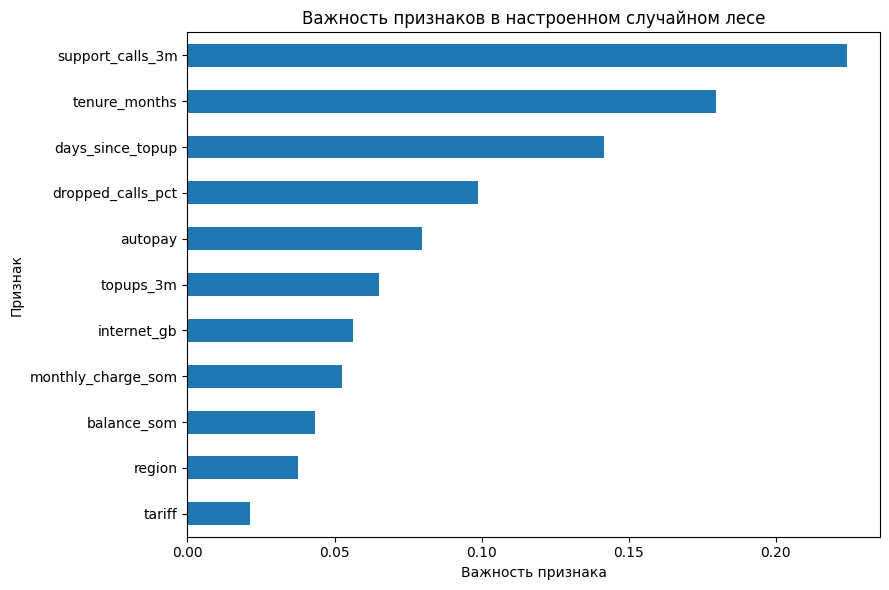

In [24]:
# Получаем важность преобразованных признаков
best_preprocessor = forest_tuned.named_steps["preprocessor"]
best_forest = forest_tuned.named_steps["classifier"]

feature_names = best_preprocessor.get_feature_names_out()
importances = best_forest.feature_importances_

importance_df = pd.DataFrame({
    "Признак": feature_names,
    "Важность": importances
})

# Объединяем категории region и tariff в исходные признаки
def original_feature(name):
    name = name.replace("cat__", "").replace("remainder__", "")

    if name.startswith("region_"):
        return "region"
    if name.startswith("tariff_"):
        return "tariff"

    return name

importance_df["Исходный признак"] = (
    importance_df["Признак"].apply(original_feature)
)

# Суммируем важность категорий каждого исходного признака
importance_original = (
    importance_df.groupby("Исходный признак")["Важность"]
    .sum()
    .sort_values(ascending=True)
)

display(
    importance_original.sort_values(ascending=False)
    .rename("Важность")
    .to_frame()
    .round(4)
)

# График важности признаков
plt.figure(figsize=(9, 6))
importance_original.plot(kind="barh")
plt.xlabel("Важность признака")
plt.ylabel("Признак")
plt.title("Важность признаков в настроенном случайном лесе")
plt.tight_layout()
plt.show()

In [25]:

from sklearn.model_selection import cross_val_score

# Признаки от наименее важного к наиболее важному
features_to_remove = importance_original.sort_values().index.tolist()

best_params = grid_search.best_params_

def make_feature_pipeline(features):
    categorical = [
        feature for feature in ["region", "tariff"]
        if feature in features
    ]

    numeric = [
        feature for feature in features
        if feature not in categorical
    ]

    transformers = []

    if categorical:
        transformers.append((
            "cat",
            OneHotEncoder(handle_unknown="ignore"),
            categorical
        ))

    preprocessor_reduced = ColumnTransformer(
        transformers=transformers,
        remainder="passthrough"
    )

    return Pipeline([
        ("preprocessor", preprocessor_reduced),
        ("classifier", RandomForestClassifier(
            n_estimators=best_params["classifier__n_estimators"],
            max_depth=best_params["classifier__max_depth"],
            min_samples_leaf=best_params["classifier__min_samples_leaf"],
            max_features=best_params["classifier__max_features"],
            random_state=42,
            n_jobs=1
        ))
    ])


remaining_features = list(X_train.columns)
removal_results = []

# Проверяем все признаки и постепенно удаляем наименее важные
for step in range(len(features_to_remove)):
    model = make_feature_pipeline(remaining_features)

    scores = cross_val_score(
        model,
        X_train[remaining_features],
        y_train,
        cv=cv,
        scoring="roc_auc",
        n_jobs=-1
    )

    removal_results.append({
        "Удалённый признак": (
            "Нет — все признаки" if step == 0
            else features_to_remove[step - 1]
        ),
        "Количество признаков": len(remaining_features),
        "Средний ROC-AUC": scores.mean(),
        "Стандартное отклонение": scores.std()
    })

    # Не удаляем последний оставшийся признак
    if step < len(features_to_remove) - 1:
        remaining_features.remove(features_to_remove[step])

removal_df = pd.DataFrame(removal_results)
display(removal_df.round(4))


,Удалённый признак,Количество признаков,Средний ROC-AUC,Стандартное отклонение
0,Нет — все признаки,11,0.7694,0.0124
1,tariff,10,0.7693,0.0145
2,region,9,0.7685,0.0183
3,balance_som,8,0.7707,0.0144
4,monthly_charge_som,7,0.7681,0.0171
5,internet_gb,6,0.7662,0.0176
6,topups_3m,5,0.7673,0.0198
7,autopay,4,0.7456,0.0189
8,dropped_calls_pct,3,0.7369,0.0123
9,days_since_topup,2,0.7020,0.0204


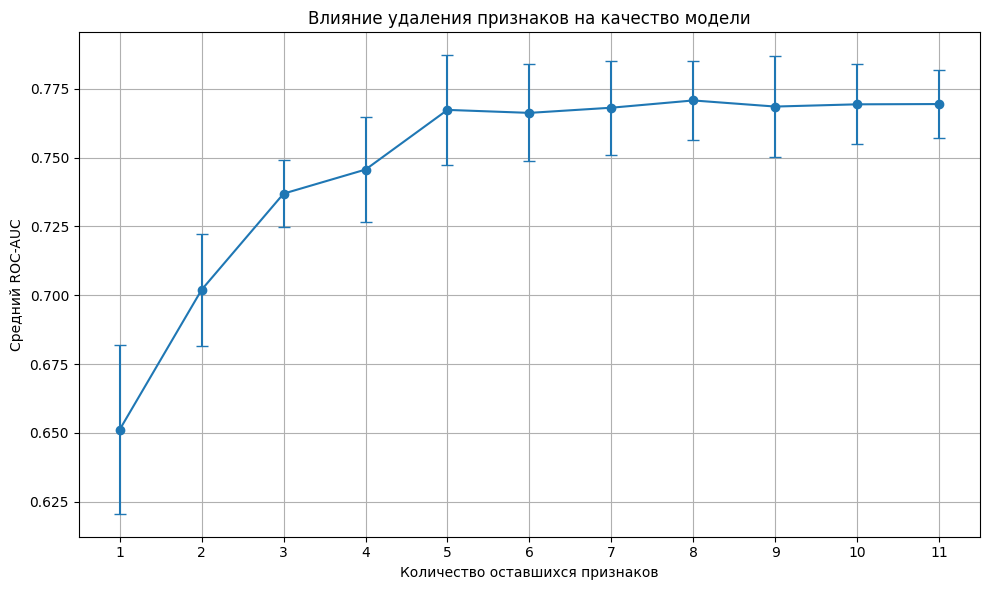

In [26]:
plt.figure(figsize=(10, 6))

plt.errorbar(
    removal_df["Количество признаков"],
    removal_df["Средний ROC-AUC"],
    yerr=removal_df["Стандартное отклонение"],
    marker="o",
    capsize=4
)

plt.xlabel("Количество оставшихся признаков")
plt.ylabel("Средний ROC-AUC")
plt.title("Влияние удаления признаков на качество модели")
plt.xticks(range(1, 12))
plt.grid(True)
plt.tight_layout()
plt.show()

In [27]:
# Оставляем 8 признаков, удаляя три наименее важных
selected_features = [
    feature for feature in X_train.columns
    if feature not in ["tariff", "region", "balance_som"]
]

reduced_model = make_feature_pipeline(selected_features)

reduced_scores = cross_val_score(
    reduced_model,
    X_train[selected_features],
    y_train,
    cv=cv,
    scoring="roc_auc",
    n_jobs=-1
)

print("Оставшиеся признаки:", selected_features)
print("Количество признаков:", len(selected_features))
print("ROC-AUC CV:", round(reduced_scores.mean(), 4))
print("Стандартное отклонение:", round(reduced_scores.std(), 4))

Оставшиеся признаки: ['tenure_months', 'monthly_charge_som', 'internet_gb', 'support_calls_3m', 'autopay', 'days_since_topup', 'topups_3m', 'dropped_calls_pct']
Количество признаков: 8
ROC-AUC CV: 0.7707
Стандартное отклонение: 0.0144


## 12. Итоговый вывод

В ходе практической работы была построена модель случайного леса (Random Forest) для прогнозирования оттока абонентов. Использовался синтетический датасет из 3000 записей. Для обучения и тестирования данные были разделены в соотношении 80/20 с сохранением пропорций классов.

Были сравнены Decision Tree, Random Forest с параметрами по умолчанию и настроенный Random Forest. Настройка гиперпараметров с помощью GridSearchCV позволила получить ROC-AUC **0.778** на тестовой выборке при лучшем среднем ROC-AUC **0.769** на кросс-валидации. При этом F1-score настроенной модели составил **0.512**, поэтому улучшение ROC-AUC не означает улучшения всех метрик одновременно.

По оценке важности признаков наибольший вклад внесли `support_calls_3m`, `tenure_months` и `days_since_topup`. В эксперименте по последовательному удалению признаков удаление `tariff`, `region` и `balance_som` не привело к заметному снижению среднего ROC-AUC. Для сокращённого набора из 8 признаков средний ROC-AUC составил **0.771 ± 0.014**, поэтому эти признаки можно рассматривать как кандидатов на исключение.

Количество деревьев также проверялось с помощью OOB-оценки. Наибольшее значение в проведённом эксперименте наблюдалось при 200 деревьях, а при 400 деревьях улучшения не было. При этом GridSearchCV выбрал 300 деревьев для итоговой модели.

Таким образом, случайный лес показал лучшие результаты по ROC-AUC, чем дерево решений. При интерпретации важности признаков следует учитывать, что она показывает связь признаков с предсказаниями модели, но не доказывает причинно-следственную связь. Результаты относятся к синтетическим данным и не гарантируют такого же качества на реальных данных оператора.